In [ ]:
!pip install -q datasets librosa tensorflow scikit-learn matplotlib

import numpy as np
import librosa
import tensorflow as tf
import matplotlib.pyplot as plt

from datasets import load_dataset
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, AveragePooling2D,
    GlobalAveragePooling2D, Dense, Dropout, Concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
ds = load_dataset(
    "SpeechAntiSpoofingBenchmarks/DFADD",
    split="test"
)

print(ds)
print("Dataset columns:", ds.column_names)

README.md:   0%|          | 0.00/3.70k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  239MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/3755 [00:00<?, ? examples/s]

Dataset({
    features: ['path', 'audio', 'label', 'notes'],
    num_rows: 3755
})
Dataset columns: ['path', 'audio', 'label', 'notes']


In [ ]:
X = []
y = []

for i, row in enumerate(ds):
    audio = row["audio"]
    signal = np.asarray(audio["array"], dtype=np.float32)
    sr = audio["sampling_rate"]

    # Generate mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=signal,
        sr=sr,
        n_mels=128
    )

    mel = librosa.power_to_db(mel, ref=np.max)

    # Normalize values
    mel = (mel - mel.min()) / (mel.max() - mel.min() + 1e-8)

    # Resize to 128 x 128
    mel = tf.image.resize(
        mel[..., np.newaxis],
        (128, 128)
    ).numpy()

    # Convert to 3 channels
    mel = np.repeat(mel, 3, axis=-1) * 255.0

    X.append(mel)
    y.append(row["label"])

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1} audio samples")

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int32)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Labels:", np.unique(y))

Processed 100 audio samples
Processed 200 audio samples
Processed 300 audio samples
Processed 400 audio samples
Processed 500 audio samples
Processed 600 audio samples
Processed 700 audio samples
Processed 800 audio samples
Processed 900 audio samples
Processed 1000 audio samples
Processed 1100 audio samples
Processed 1200 audio samples
Processed 1300 audio samples
Processed 1400 audio samples
Processed 1500 audio samples
Processed 1600 audio samples
Processed 1700 audio samples
Processed 1800 audio samples
Processed 1900 audio samples
Processed 2000 audio samples
Processed 2100 audio samples
Processed 2200 audio samples
Processed 2300 audio samples
Processed 2400 audio samples
Processed 2500 audio samples
Processed 2600 audio samples
Processed 2700 audio samples
Processed 2800 audio samples
Processed 2900 audio samples
Processed 3000 audio samples
Processed 3100 audio samples
Processed 3200 audio samples
Processed 3300 audio samples
Processed 3400 audio samples
Processed 3500 audio sa

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3004
Testing samples: 751


In [ ]:
def inception_module(x, filters):
    f1, f3_reduce, f3, f5_reduce, f5, f_pool = filters

    # 1x1 convolution branch
    branch1 = Conv2D(
        f1, (1, 1), padding="same", activation="relu"
    )(x)

    # 1x1 followed by 3x3 convolution
    branch3 = Conv2D(
        f3_reduce, (1, 1), padding="same", activation="relu"
    )(x)
    branch3 = Conv2D(
        f3, (3, 3), padding="same", activation="relu"
    )(branch3)

    # 1x1 followed by 5x5 convolution
    branch5 = Conv2D(
        f5_reduce, (1, 1), padding="same", activation="relu"
    )(x)
    branch5 = Conv2D(
        f5, (5, 5), padding="same", activation="relu"
    )(branch5)

    # Pooling branch
    branch_pool = MaxPooling2D(
        (3, 3), strides=(1, 1), padding="same"
    )(x)
    branch_pool = Conv2D(
        f_pool, (1, 1), padding="same", activation="relu"
    )(branch_pool)

    return Concatenate(axis=-1)(
        [branch1, branch3, branch5, branch_pool]
    )


inputs = Input(shape=(128, 128, 3))

# Initial convolution and pooling
x = Conv2D(
    64, (7, 7), strides=2, padding="same", activation="relu"
)(inputs)
x = MaxPooling2D((3, 3), strides=2, padding="same")(x)

x = Conv2D(64, (1, 1), activation="relu", padding="same")(x)
x = Conv2D(192, (3, 3), activation="relu", padding="same")(x)
x = MaxPooling2D((3, 3), strides=2, padding="same")(x)

# Inception modules
x = inception_module(x, [64, 96, 128, 16, 32, 32])
x = inception_module(x, [128, 128, 192, 32, 96, 64])
x = MaxPooling2D((3, 3), strides=2, padding="same")(x)

x = inception_module(x, [192, 96, 208, 16, 48, 64])
x = inception_module(x, [160, 112, 224, 24, 64, 64])
x = inception_module(x, [128, 128, 256, 24, 64, 64])

# Classification layers
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
outputs = Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs, name="GoogLeNet_VoiceGuard")

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "GoogLeNet_VoiceGuard"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      9,472 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      4,160 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │    110,784 │ conv2d_1[0][0]    │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     18,528 │ max_pooling2d_1[… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │      3,088 │ max_pooling2d_1[… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ max_pooling2d_1[… │
│ (MaxPooling2D)      │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │     12,352 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │    110,720 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │     12,832 │ conv2d_6[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │      6,176 │ max_pooling2d_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_3[0][0],   │
│ (Concatenate)       │ 256)              │            │ conv2d_5[0][0],   │
│                     │                   │            │ conv2d_7[0][0],   │
│                     │                   │            │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │     32,896 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 16, 16,    │      8,224 │ concatenate[0][0] │
│                     │ 32)               │            │                 

 Total params: 2,012,801 (7.68 MB)

 Trainable params: 2,012,801 (7.68 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 208s 1s/step - accuracy: 0.7998 - loss: 0.5055 - val_accuracy: 0.8469 - val_loss: 0.3535 - learning_rate: 1.0000e-04
Epoch 2/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 196s 1s/step - accuracy: 0.8793 - loss: 0.3002 - val_accuracy: 0.9035 - val_loss: 0.2646 - learning_rate: 1.0000e-04
Epoch 3/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 191s 1s/step - accuracy: 0.9147 - loss: 0.2143 - val_accuracy: 0.9201 - val_loss: 0.1855 - learning_rate: 1.0000e-04
Epoch 4/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.9467 - loss: 0.1403 - val_accuracy: 0.9418 - val_loss: 0.1391 - learning_rate: 1.0000e-04
Epoch 5/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.9680 - loss: 0.0940 - val_accuracy: 0.9717 - val_loss: 0.1047 - learning_rate: 1.0000e-04
Epoch 6/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.9754 - loss: 0.0695 - val_accuracy: 0.9667 - val_loss: 0.0935 - learning_rate: 1.0000e-04
Epoch 7/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 204s 1s/step - acc

In [7]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).ravel()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

24/24 ━━━━━━━━━━━━━━━━━━━━ 12s 520ms/step - accuracy: 0.9854 - loss: 0.0372
Test Loss: 0.0372
Test Accuracy: 98.54%
24/24 ━━━━━━━━━━━━━━━━━━━━ 13s 539ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       151
           1       0.99      0.99      0.99       600

    accuracy                           0.99       751
   macro avg       0.97      0.98      0.98       751
weighted avg       0.99      0.99      0.99       751


Confusion Matrix:
[[148   3]
 [  8 592]]


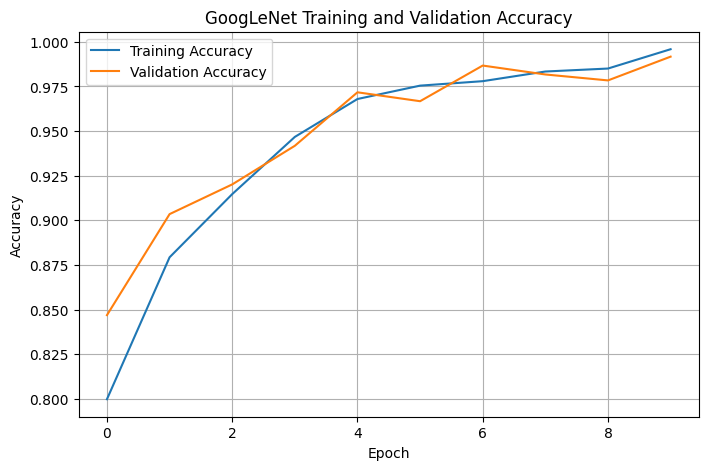

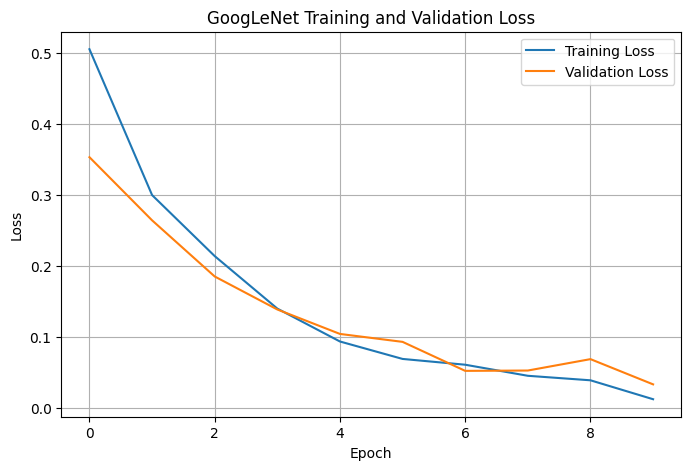

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("GoogLeNet Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("GoogLeNet Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()